In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
from pathlib import Path
current_dir=Path.cwd()
print("Current working directory:",current_dir)


Current working directory: c:\Users\ramya\OneDrive\Desktop\Ecommerce_Intelligence_Platform\notebooks


In [16]:
#Check possible locations of our data folder
possible_paths=[current_dir / "data",
                current_dir.parent / "data"
                
                ]

#find the correct data folder

data_dir = None
        
for path in possible_paths:
    if path.exists():
        data_dir = path
        break

#Display the result
if data_dir is not None:
    print("Data folder found at:",data_dir)
else:
    print("Data folder not found. Check the folder structure.") 



Data folder found at: c:\Users\ramya\OneDrive\Desktop\Ecommerce_Intelligence_Platform\data


In [17]:
csv_files = list(data_dir.glob("*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files: 10
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
orders_with_payments.csv
product_category_name_translation.csv


In [18]:
#load the orders dataset
orders=pd.read_csv(data_dir/"olist_orders_dataset.csv")


print("Orders dataset loaded successfully!")

Orders dataset loaded successfully!


In [12]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [19]:
print("Number of rows:",orders.shape[0])
print("Number of columns:",orders.shape[1])

Number of rows: 99441
Number of columns: 8


In [20]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [15]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [21]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [22]:
print("Total duplicate rows:",orders.duplicated().sum())

Total duplicate rows: 0


In [18]:
orders.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [23]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [24]:
orders.groupby('order_status')['order_delivered_customer_date'].apply(lambda x:x.isnull().sum())

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

In [25]:
print("Total order IDs:", orders['order_id'].count())

print("Unique order IDs:", orders['order_id'].nunique())

print("Duplicate order IDs:", orders['order_id'].duplicated().sum())

Total order IDs: 99441
Unique order IDs: 99441
Duplicate order IDs: 0


In [26]:
missing_percentage = (
    orders.isnull().sum() / len(orders)
) * 100

print(missing_percentage.round(2))

order_id                         0.00
customer_id                      0.00
order_status                     0.00
order_purchase_timestamp         0.00
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
order_estimated_delivery_date    0.00
dtype: float64


In [27]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for column in date_columns:
    print(column, ":", orders[column].dtype)

order_purchase_timestamp : str
order_approved_at : str
order_delivered_carrier_date : str
order_delivered_customer_date : str
order_estimated_delivery_date : str


In [30]:
#create a separate copy of our orders dataset

orders_clean=orders.copy()

# Identify date columns
date_columns=[
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

# Convert string columns into datetime format
for column in date_columns:
    orders_clean[column]=pd.to_datetime(
        orders_clean[column],
        errors='coerce'
    )
    
print("Date conversion completed!")


Date conversion completed!


In [31]:
orders_clean[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [32]:
orders_clean[date_columns].isnull().sum()

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [33]:
orders_clean['actual_delivery_days'] = (
    orders_clean['order_delivered_customer_date']
    - orders_clean['order_purchase_timestamp']
).dt.total_seconds() / 86400

In [10]:
orders_clean[[
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'actual_delivery_days'
]].head(10)

,order_purchase_timestamp,order_delivered_customer_date,actual_delivery_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877
5,2017-07-09 21:57:05,2017-07-26 10:57:55,16.542245
6,2017-04-11 12:22:08,NaT,NaN
7,2017-05-16 13:10:30,2017-05-26 12:55:51,9.989826
8,2017-01-23 18:29:09,2017-02-02 14:08:10,9.818762
9,2017-07-29 11:55:02,2017-08-16 17:14:30,18.221852


In [34]:
average_delivery=orders_clean['actual_delivery_days'].mean()

print("Average delivery time:", round(average_delivery,2),"days")

Average delivery time: 12.56 days


In [35]:
print("Minimum delivery time:",
      orders_clean['actual_delivery_days'].min())

print("Maximum delivery time:",
      orders_clean['actual_delivery_days'].max())

Minimum delivery time: 0.5334143518518518
Maximum delivery time: 209.6286111111111


In [36]:
print("Orders with recorded delivery time:",
      orders_clean['actual_delivery_days'].count())

Orders with recorded delivery time: 96476


In [37]:
delivered_orders=orders_clean[
    orders_clean['order_status']=='delivered'
]
print("Total delivered orders:",len(delivered_orders))

Total delivered orders: 96478


In [38]:
delivered_average=delivered_orders['actual_delivery_days'].mean()

print("Average delivery time for delivered orders:",
      round(delivered_average, 2), "days")

Average delivery time for delivered orders: 12.56 days


In [16]:
longest_delivery = orders_clean.loc[
    orders_clean['actual_delivery_days'].idxmax()
]

longest_delivery

order_id                         ca07593549f1816d26a572e06dc1eab6
customer_id                      75683a92331068e2d281b11a7866ba44
order_status                                            delivered
order_purchase_timestamp                      2017-02-21 23:31:27
order_approved_at                             2017-02-23 02:35:15
order_delivered_carrier_date                  2017-03-08 13:47:46
order_delivered_customer_date                 2017-09-19 14:36:39
order_estimated_delivery_date                 2017-03-22 00:00:00
actual_delivery_days                                   209.628611
Name: 19590, dtype: object

In [39]:
delivered_orders = orders_clean[
    orders_clean['order_status'] == 'delivered'
].copy()

delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

In [18]:
delivered_orders[[
    'order_id',
    'order_estimated_delivery_date',
    'order_delivered_customer_date',
    'delivery_delay_days'
]].head(10)

,order_id,order_estimated_delivery_date,order_delivered_customer_date,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-15,2017-12-02 00:28:42,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-26,2018-02-16 18:17:02,-9.238171
5,a4591c265e18cb1dcee52889e2d8acc3,2017-08-01,2017-07-26 10:57:55,-5.543113
7,6514b8ad8028c9f2cc2374ded245783f,2017-06-07,2017-05-26 12:55:51,-11.461215
8,76c6e866289321a7c93b82b54852dc33,2017-03-06,2017-02-02 14:08:10,-31.410995
9,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-23,2017-08-16 17:14:30,-6.281597
10,e6ce16cb79ec1d90b1da9085a6118aeb,2017-06-07,2017-05-29 11:18:31,-8.528808


In [40]:
delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'].dt.normalize()
    - delivered_orders['order_estimated_delivery_date'].dt.normalize()
).dt.days

In [20]:
early_orders = (
    delivered_orders['delivery_delay_days'] < 0
).sum()

on_time_orders = (
    delivered_orders['delivery_delay_days'] == 0
).sum()

late_orders = (
    delivered_orders['delivery_delay_days'] > 0
).sum()

missing_delay = (
    delivered_orders['delivery_delay_days'].isna()
).sum()

print("Early orders:", early_orders)
print("On-time orders:", on_time_orders)
print("Late orders:", late_orders)
print("Orders with missing delay:", missing_delay)

Early orders: 88644
On-time orders: 1292
Late orders: 6534
Orders with missing delay: 8


In [41]:
total_orders = (
    early_orders + on_time_orders + late_orders
)

early_percentage = (early_orders / total_orders) * 100
on_time_percentage = (on_time_orders / total_orders) * 100
late_percentage = (late_orders / total_orders) * 100

print("Early delivery:", round(early_percentage, 2), "%")
print("Exact-date delivery:", round(on_time_percentage, 2), "%")
print("Late delivery:", round(late_percentage, 2), "%")

NameError: name 'early_orders' is not defined

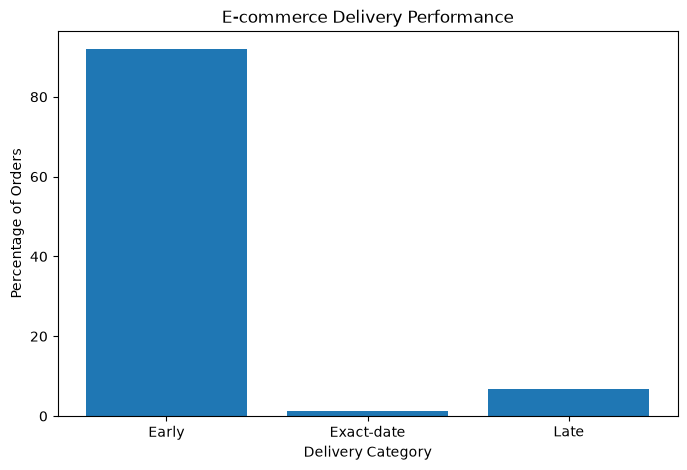

In [22]:
categories=['Early','Exact-date','Late']

percentages=[
    early_percentage,
    on_time_percentage,
    late_percentage
]

plt.figure(figsize=(8,5))

plt.bar(categories,percentages)

plt.title('E-commerce Delivery Performance')
plt.xlabel('Delivery Category')
plt.ylabel('Percentage of Orders')

plt.show()


In [42]:
delivered_orders['actual_delivery_days'].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: actual_delivery_days, dtype: float64

In [43]:
very_slow_orders = delivered_orders[
    delivered_orders['actual_delivery_days'] > 30
]

print("Orders taking more than 30 days:", len(very_slow_orders))

Orders taking more than 30 days: 4550


In [44]:
slow_delivery_percentage = (
    len(very_slow_orders) / delivered_orders['actual_delivery_days'].count()
) * 100

print("Orders taking more than 30 days:", round(slow_delivery_percentage, 2), "%")

Orders taking more than 30 days: 4.72 %


In [26]:
very_slow_orders[
    ['order_id', 'actual_delivery_days', 'delivery_delay_days']
].sort_values(
    by='actual_delivery_days',
    ascending=False
).head(10)

,order_id,actual_delivery_days,delivery_delay_days
19590,ca07593549f1816d26a572e06dc1eab6,209.628611,181.0
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.351759,188.0
61610,440d0d17af552815d15a9e41abe49359,195.634016,165.0
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.850174,155.0
89130,285ab9426d6982034523a855f55a885e,194.633611,166.0
38509,0f4519c5f1c541ddec9f21b3bddd533a,194.049583,161.0
11399,47b40429ed8cce3aee9199792275433f,191.463542,175.0
81401,2fe324febf907e3ea3f2aa9650869fa5,189.863160,167.0
54480,2d7561026d542c8dbd8f0daeadf67a43,188.134618,159.0
68769,c27815f7e3dd0b926b58552628481575,187.743843,162.0


In [45]:
slow_and_late = very_slow_orders[
    very_slow_orders['delivery_delay_days'] > 0
]

slow_but_on_time_or_early = very_slow_orders[
    very_slow_orders['delivery_delay_days'] <= 0
]

print("Slow and late orders:", len(slow_and_late))
print("Slow but on-time or early orders:", len(slow_but_on_time_or_early))

Slow and late orders: 3581
Slow but on-time or early orders: 969


In [46]:
delivered_orders['purchase_month'] = (
    delivered_orders['order_purchase_timestamp'].dt.to_period('M')
)

In [47]:
delivered_orders[
    ['order_purchase_timestamp', 'purchase_month']
].head(10)

,order_purchase_timestamp,purchase_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02
5,2017-07-09 21:57:05,2017-07
7,2017-05-16 13:10:30,2017-05
8,2017-01-23 18:29:09,2017-01
9,2017-07-29 11:55:02,2017-07
10,2017-05-16 19:41:10,2017-05


In [56]:
monthly_late_orders = (
    delivered_orders[
        delivered_orders['delivery_delay_days'] > 0
    ]
    .groupby('purchase_month')
    .size()
)

monthly_late_orders

purchase_month
2016-09       1
2016-10       2
2017-01      22
2017-02      49
2017-03     116
2017-04     151
2017-05     106
2017-06      95
2017-07     108
2017-08     122
2017-09     182
2017-10     187
2017-11     904
2017-12     411
2018-01     403
2018-02     926
2018-03    1328
2018-04     306
2018-05     443
2018-06      71
2018-07     208
2018-08     393
Freq: M, dtype: int64

In [54]:
monthly_total_orders = (
    delivered_orders
    .groupby('purchase_month')
    .size()
)

monthly_total_orders

purchase_month
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, dtype: int64

In [58]:
monthly_late_percentage = (
    monthly_late_orders / monthly_total_orders
) * 100

monthly_late_percentage = monthly_late_percentage.round(2)

monthly_late_percentage

purchase_month
2016-09    100.00
2016-10      0.75
2016-12       NaN
2017-01      2.93
2017-02      2.96
2017-03      4.56
2017-04      6.56
2017-05      2.99
2017-06      3.03
2017-07      2.79
2017-08      2.91
2017-09      4.39
2017-10      4.18
2017-11     12.40
2017-12      7.46
2018-01      5.70
2018-02     14.13
2018-03     18.96
2018-04      4.50
2018-05      6.56
2018-06      1.16
2018-07      3.38
2018-08      6.19
Freq: M, dtype: float64

In [59]:
worst_month = monthly_late_percentage.idxmax()
worst_rate = monthly_late_percentage.max()

print("Month with highest late-delivery rate:", worst_month)
print("Late-delivery rate:", worst_rate, "%")

Month with highest late-delivery rate: 2016-09
Late-delivery rate: 100.0 %


In [34]:
monthly_late_orders = monthly_late_orders.reindex(
    monthly_total_orders.index,
    fill_value=0
)

monthly_late_percentage = (
    monthly_late_orders / monthly_total_orders
) * 100

monthly_late_percentage = monthly_late_percentage.round(2)

monthly_late_percentage

purchase_month
2016-09    100.00
2016-10      0.75
2016-12      0.00
2017-01      2.93
2017-02      2.96
2017-03      4.56
2017-04      6.56
2017-05      2.99
2017-06      3.03
2017-07      2.79
2017-08      2.91
2017-09      4.39
2017-10      4.18
2017-11     12.40
2017-12      7.46
2018-01      5.70
2018-02     14.13
2018-03     18.96
2018-04      4.50
2018-05      6.56
2018-06      1.16
2018-07      3.38
2018-08      6.19
Freq: M, dtype: float64

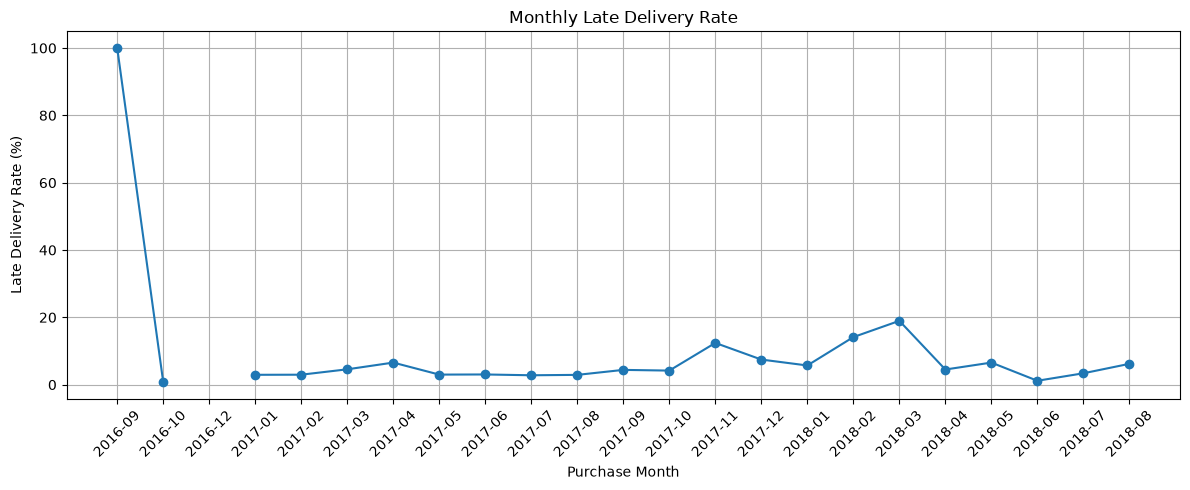

In [60]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_late_percentage.index.astype(str),
    monthly_late_percentage.values,
    marker='o'
)

plt.title('Monthly Late Delivery Rate')
plt.xlabel('Purchase Month')
plt.ylabel('Late Delivery Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [61]:
orders_clean = orders.copy()

In [62]:
missing_summary=pd.DataFrame({
    'Missing_Count':orders_clean.isnull().sum(),
    'Missing_Percentage':(
        orders_clean.isnull().sum()/len(orders_clean)
    )*100
})

missing_summary

,Missing_Count,Missing_Percentage
order_id,0,0.000000
customer_id,0,0.000000
order_status,0,0.000000
order_purchase_timestamp,0,0.000000
order_approved_at,160,0.160899
order_delivered_carrier_date,1783,1.793023
order_delivered_customer_date,2965,2.981668
order_estimated_delivery_date,0,0.000000


In [66]:
missing_delivery = orders_clean[
    orders_clean['order_delivered_customer_date'].isnull()
]

missing_delivery['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [65]:
delivered_missing_dates = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_delivered_customer_date'].isnull())
]

delivered_missing_dates

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [67]:
print(
    "Missing carrier dates:",
    delivered_missing_dates['order_delivered_carrier_date'].isnull().sum()
)

print(
    "Missing customer delivery dates:",
    delivered_missing_dates['order_delivered_customer_date'].isnull().sum()
)

Missing carrier dates: 1
Missing customer delivery dates: 8


In [68]:
print("Original rows:", len(orders))
print("Working copy rows:", len(orders_clean))

print(
    "Original missing delivery dates:",
    orders['order_delivered_customer_date'].isnull().sum()
)

print(
    "Working copy missing delivery dates:",
    orders_clean['order_delivered_customer_date'].isnull().sum()
)

Original rows: 99441
Working copy rows: 99441
Original missing delivery dates: 2965
Working copy missing delivery dates: 2965


In [69]:
duplicate_rows = orders_clean.duplicated().sum()

print("Completely duplicated rows:", duplicate_rows)

Completely duplicated rows: 0


In [70]:
duplicate_order_ids = orders_clean['order_id'].duplicated().sum()

print("Duplicate order IDs:", duplicate_order_ids)

Duplicate order IDs: 0


In [71]:
orders_clean.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [72]:
print("Original dataframe:")
print(orders.dtypes)

print("\nWorking dataframe:")
print(orders_clean.dtypes)


Original dataframe:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Working dataframe:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [73]:
orders_clean = orders.copy()

In [74]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors='coerce'
    )

In [75]:
orders_clean.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [76]:
invalid_approval_dates = orders_clean[
    orders_clean['order_approved_at']
    < orders_clean['order_purchase_timestamp']
]

print("Orders approved before purchase:", len(invalid_approval_dates))

Orders approved before purchase: 0


In [77]:
invalid_carrier_dates = orders_clean[
    orders_clean['order_delivered_carrier_date']
    < orders_clean['order_approved_at']
]

print(
    "Orders handed to carrier before approval:",
    len(invalid_carrier_dates)
)

Orders handed to carrier before approval: 1359


In [51]:
invalid_carrier_dates[[
    'order_id',
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date'
]].head(10)

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14
199,58d4c4747ee059eeeb865b349b41f53a,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00
210,412fccb2b44a99b36714bca3fef8ad7b,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00
415,56a4ac10a4a8f2ba7693523bb439eede,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00
481,32e4fa9bb468884309b58b9348de70c3,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00
483,4df92d82d79c3b52c7138679fa9b07fc,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00
585,16e38caa92e342c7780f68832f832d4d,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
817,6051e6d3da9a50b7325cbe9c81025062,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00


In [78]:
invalid_carrier_dates = invalid_carrier_dates.copy()

invalid_carrier_dates['approval_time_difference_hours'] = (
    invalid_carrier_dates['order_approved_at']
    - invalid_carrier_dates['order_delivered_carrier_date']
).dt.total_seconds() / 3600

In [79]:
invalid_carrier_dates[
    ['order_id', 'approval_time_difference_hours']
].head(10)

,order_id,approval_time_difference_hours
15,dcb36b511fcac050b97cd5c05de84dc3,32.617222
64,688052146432ef8253587b930b01a06d,23.102222
199,58d4c4747ee059eeeb865b349b41f53a,58.581389
210,412fccb2b44a99b36714bca3fef8ad7b,0.131389
415,56a4ac10a4a8f2ba7693523bb439eede,81.469167
481,32e4fa9bb468884309b58b9348de70c3,1.718333
483,4df92d82d79c3b52c7138679fa9b07fc,80.747778
585,16e38caa92e342c7780f68832f832d4d,1.727500
615,b9afddbdcfadc9a87b41a83271c3e888,0.636944
817,6051e6d3da9a50b7325cbe9c81025062,28.290556


In [80]:
invalid_carrier_dates['approval_time_difference_hours'].describe()

count    1359.000000
mean       24.751987
std       115.307793
min         0.005833
25%         1.415417
50%        17.167778
75%        25.956667
max      4109.256111
Name: approval_time_difference_hours, dtype: float64

In [81]:
largest_time_difference = invalid_carrier_dates.loc[
    invalid_carrier_dates['approval_time_difference_hours'].idxmax()
]

largest_time_difference

order_id                          7c48bb55e8e4f7e56d412e9653db37bc
customer_id                       34ef6181341eb36c47fd601c46878f00
order_status                                             delivered
order_purchase_timestamp                       2018-07-16 18:40:53
order_approved_at                              2018-07-16 18:50:22
order_delivered_carrier_date                   2018-01-26 13:35:00
order_delivered_customer_date                  2018-07-23 20:04:45
order_estimated_delivery_date                  2018-08-07 00:00:00
approval_time_difference_hours                         4109.256111
Name: 25883, dtype: object

In [82]:
invalid_purchase_carrier = orders_clean[
    orders_clean['order_delivered_carrier_date']
    < orders_clean['order_purchase_timestamp']
]

print(
    "Carrier handover before purchase:",
    len(invalid_purchase_carrier)
)

Carrier handover before purchase: 166


In [57]:
invalid_purchase_carrier[[
    'order_id',
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]].head(10)

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37
1111,ad133696906f6a78826daa0911b7daec,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00,2018-06-22 18:09:37
1329,74e033208dc13a7b8127eb8e73d09b76,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00,2018-05-07 23:06:36
1372,a6b58794fd2ba533359a76c08df576e3,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00,2018-05-19 19:33:32
1864,5792e0b1c8c8a2bf53af468c9a422c88,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00,2018-07-30 14:45:02
2760,c3eb293fd154223498b6551a728203e8,2018-07-19 14:06:04,2018-07-19 14:22:51,2018-07-19 13:49:00,2018-07-24 19:35:36
3473,b0c2a7d04b165525254254a728c50a4e,2018-06-07 13:28:30,2018-06-07 13:57:22,2018-06-07 13:22:00,2018-06-21 17:36:43
3661,2033a4586b5bec3229ebc1675a8ae092,2018-06-12 10:10:25,2018-06-12 10:39:59,2018-06-12 10:09:00,2018-06-19 14:08:27
4114,08adcddad19d3acf37d1fa01cb9ded1e,2018-06-27 11:16:44,2018-06-27 11:30:56,2018-06-27 10:57:00,2018-06-29 17:39:53
4159,dee6298ce7d1fb2645141ef9972157aa,2018-04-30 14:06:12,2018-04-30 14:15:24,2018-04-30 12:59:00,NaT


In [83]:
carrier_before_delivery = invalid_purchase_carrier[
    invalid_purchase_carrier['order_delivered_customer_date']
    < invalid_purchase_carrier['order_delivered_carrier_date']
]

print(
    "Customer delivery before carrier handover:",
    len(carrier_before_delivery)
)

Customer delivery before carrier handover: 0


In [84]:
invalid_delivery_dates = orders_clean[
    orders_clean['order_delivered_customer_date']
    < orders_clean['order_purchase_timestamp']
]

print(
    "Customer delivery before purchase:",
    len(invalid_delivery_dates)
)

Customer delivery before purchase: 0


In [85]:
missing_estimated_dates = delivered_orders[
    delivered_orders['order_estimated_delivery_date'].isnull()
]

print(
    "Delivered orders with missing estimated dates:",
    len(missing_estimated_dates)
)

Delivered orders with missing estimated dates: 0


In [86]:
orders_clean['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [87]:
delivered_orders_clean = orders_clean[
    orders_clean['order_status'] == 'delivered'
].copy()

print("Delivered orders:", len(delivered_orders_clean))

Delivered orders: 96478


In [88]:
non_delivered_orders = orders_clean[
    orders_clean['order_status'] != 'delivered'
].copy()

print("Non-delivered orders:", len(non_delivered_orders))

Non-delivered orders: 2963


In [89]:
print("Delivered:", len(delivered_orders_clean))
print("Non-delivered:", len(non_delivered_orders))

print(
    "Total:",
    len(delivered_orders_clean) + len(non_delivered_orders)
)

Delivered: 96478
Non-delivered: 2963
Total: 99441


In [90]:
non_delivered_orders['order_status'].value_counts()


order_status
shipped        1107
canceled        625
unavailable     609
invoiced        314
processing      301
created           5
approved          2
Name: count, dtype: int64

In [91]:
canceled_orders = non_delivered_orders[
    non_delivered_orders['order_status'] == 'canceled'
]

print("Canceled orders:", len(canceled_orders))

Canceled orders: 625


In [92]:
total_orders = len(orders_clean)
canceled_count = len(canceled_orders)

cancellation_percentage = (
    canceled_count / total_orders
) * 100

print("Cancellation percentage:", round(cancellation_percentage, 2), "%")

Cancellation percentage: 0.63 %


In [93]:
canceled_orders = canceled_orders.copy()

canceled_orders['purchase_month'] = (
    canceled_orders['order_purchase_timestamp'].dt.to_period('M')
)

In [69]:
canceled_orders['purchase_month'].value_counts().sort_index()

purchase_month
2016-09     2
2016-10    24
2017-01     3
2017-02    17
2017-03    33
2017-04    18
2017-05    29
2017-06    16
2017-07    28
2017-08    27
2017-09    20
2017-10    26
2017-11    37
2017-12    11
2018-01    34
2018-02    73
2018-03    26
2018-04    15
2018-05    24
2018-06    18
2018-07    41
2018-08    84
2018-09    15
2018-10     4
Freq: M, Name: count, dtype: int64

In [94]:
orders_clean['purchase_month'] = (
    orders_clean['order_purchase_timestamp'].dt.to_period('M')
)

monthly_total_orders = (
    orders_clean.groupby('purchase_month').size()
)

print(monthly_total_orders)

purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


In [95]:
monthly_canceled_orders = (
    canceled_orders.groupby('purchase_month').size()
)

monthly_canceled_orders = monthly_canceled_orders.reindex(
    monthly_total_orders.index,
    fill_value=0
)

monthly_cancellation_rate = (
    monthly_canceled_orders / monthly_total_orders
) * 100

monthly_cancellation_rate = monthly_cancellation_rate.round(2)

print(monthly_cancellation_rate)

purchase_month
2016-09     50.00
2016-10      7.41
2016-12      0.00
2017-01      0.38
2017-02      0.96
2017-03      1.23
2017-04      0.75
2017-05      0.78
2017-06      0.49
2017-07      0.70
2017-08      0.62
2017-09      0.47
2017-10      0.56
2017-11      0.49
2017-12      0.19
2018-01      0.47
2018-02      1.09
2018-03      0.36
2018-04      0.22
2018-05      0.35
2018-06      0.29
2018-07      0.65
2018-08      1.29
2018-09     93.75
2018-10    100.00
Freq: M, dtype: float64


In [96]:
reliable_months = monthly_cancellation_rate[
    monthly_total_orders >= 1000
]

print(reliable_months.sort_values(ascending=False))

purchase_month
2018-08    1.29
2017-03    1.23
2018-02    1.09
2017-02    0.96
2017-05    0.78
2017-04    0.75
2017-07    0.70
2018-07    0.65
2017-08    0.62
2017-10    0.56
2017-06    0.49
2017-11    0.49
2017-09    0.47
2018-01    0.47
2018-03    0.36
2018-05    0.35
2018-06    0.29
2018-04    0.22
2017-12    0.19
Freq: M, dtype: float64


In [97]:
payments = pd.read_csv(
    data_dir / "olist_order_payments_dataset.csv"
)

print("Rows and columns:", payments.shape)

Rows and columns: (103886, 5)


In [98]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [99]:
payments.info()


<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [100]:
payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [101]:
unique_payment_orders = payments['order_id'].nunique()

print("Unique orders in payments:", unique_payment_orders)
print("Total payment records:", len(payments))

Unique orders in payments: 99440
Total payment records: 103886


In [102]:
orders_without_payment = orders_clean[
    ~orders_clean['order_id'].isin(payments['order_id'])
]

print("Orders without payment records:", len(orders_without_payment))

Orders without payment records: 1


In [103]:
orders_without_payment[
    ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']
]

,order_id,customer_id,order_status,order_purchase_timestamp
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38


In [104]:
orders_without_payment[
    [
        'order_id',
        'order_status',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
]

,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04


In [105]:
payment_order_counts = payments['order_id'].value_counts()

multiple_payment_orders = payment_order_counts[
    payment_order_counts > 1
]

print("Orders with multiple payment records:", len(multiple_payment_orders))

Orders with multiple payment records: 2961


In [106]:
multiple_payment_orders.head(10)


order_id
fa65dad1b0e818e3ccc5cb0e39231352    29
ccf804e764ed5650cd8759557269dc13    26
285c2e15bebd4ac83635ccc563dc71f4    22
895ab968e7bb0d5659d16cd74cd1650c    21
ee9ca989fc93ba09a6eddc250ce01742    19
fedcd9f7ccdc8cba3a18defedd1a5547    19
21577126c19bf11a0b91592e5844ba78    15
4bfcba9e084f46c8e3cb49b0fa6e6159    15
3c58bffb70dcf45f12bdf66a3c215905    14
4689b1816de42507a7d63a4617383c59    14
Name: count, dtype: int64

In [107]:
sample_order_id = multiple_payment_orders.index[0]

print("Selected order ID:", sample_order_id)

Selected order ID: fa65dad1b0e818e3ccc5cb0e39231352


In [109]:
sample_order_payments = payments[
    payments['order_id'] == sample_order_id
]

sample_order_payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
4885,fa65dad1b0e818e3ccc5cb0e39231352,27,voucher,1,66.02
9985,fa65dad1b0e818e3ccc5cb0e39231352,4,voucher,1,29.16
14321,fa65dad1b0e818e3ccc5cb0e39231352,1,voucher,1,3.71
17274,fa65dad1b0e818e3ccc5cb0e39231352,9,voucher,1,1.08
19565,fa65dad1b0e818e3ccc5cb0e39231352,10,voucher,1,12.86
23074,fa65dad1b0e818e3ccc5cb0e39231352,2,voucher,1,8.51
24879,fa65dad1b0e818e3ccc5cb0e39231352,25,voucher,1,3.68
28330,fa65dad1b0e818e3ccc5cb0e39231352,5,voucher,1,0.66
29648,fa65dad1b0e818e3ccc5cb0e39231352,6,voucher,1,5.02
32519,fa65dad1b0e818e3ccc5cb0e39231352,11,voucher,1,4.03


In [110]:
total_payment = sample_order_payments['payment_value'].sum()

print("Total payment value:", round(total_payment, 2))

Total payment value: 457.99


In [111]:
print("Number of payment records:", len(sample_order_payments))

print(
    "Payment values total:",
    sample_order_payments['payment_value'].sum()
)

print(
    "Payment methods:",
    sample_order_payments['payment_type'].unique()
)

Number of payment records: 29
Payment values total: 457.99
Payment methods: <StringArray>
['voucher']
Length: 1, dtype: str


In [112]:
payment_summary = payments.groupby('order_id').agg(
    total_payment=('payment_value', 'sum'),
    payment_record_count=('payment_value', 'count')
).reset_index()

payment_summary.head()


,order_id,total_payment,payment_record_count
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,1
2,000229ec398224ef6ca0657da4fc703e,216.87,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1


In [113]:
print("Payment summary rows:", len(payment_summary))

print(
    "Unique payment orders:",
    payments['order_id'].nunique()
)

print(
    "Duplicate order IDs in summary:",
    payment_summary['order_id'].duplicated().sum()
)

Payment summary rows: 99440
Unique payment orders: 99440
Duplicate order IDs in summary: 0


In [114]:
print("Orders dataset:", len(orders_clean))
print("Payment summary:", len(payment_summary))

Orders dataset: 99441
Payment summary: 99440


In [115]:
orders_with_payments = orders_clean.merge(
    payment_summary,
    on='order_id',
    how='left'
)

print("Joined dataset shape:", orders_with_payments.shape)

Joined dataset shape: (99441, 11)


In [116]:
orders_with_payments[
    orders_with_payments['total_payment'].isnull()
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month,total_payment,payment_record_count
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,2016-09,NaN,NaN


In [117]:
print("Total orders:", len(orders_with_payments))

print(
    "Orders with payment information:",
    orders_with_payments['total_payment'].notnull().sum()
)

print(
    "Orders without payment information:",
    orders_with_payments['total_payment'].isnull().sum()
)

Total orders: 99441
Orders with payment information: 99440
Orders without payment information: 1


In [118]:
# Save the combined dataset for our next stages
orders_with_payments.to_csv(
    data_dir / "orders_with_payments.csv",
    index=False
)

In [119]:
customers = pd.read_csv(data_dir / "olist_customers_dataset.csv")
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
sellers = pd.read_csv(data_dir / "olist_sellers_dataset.csv")
order_items = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
reviews = pd.read_csv(data_dir / "olist_order_reviews_dataset.csv")
geolocation = pd.read_csv(data_dir / "olist_geolocation_dataset.csv")
category_translation = pd.read_csv(data_dir / "product_category_name_translation.csv")

In [120]:
datasets = {
    "Customers": customers,
    "Products": products,
    "Sellers": sellers,
    "Order Items": order_items,
    "Reviews": reviews,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(name, df.shape)

Customers (99441, 5)
Products (32951, 9)
Sellers (3095, 4)
Order Items (112650, 7)
Reviews (99224, 7)
Geolocation (1000163, 5)
Category Translation (71, 2)


In [121]:
order_item_summary = order_items.groupby('order_id').agg(
    total_items=('order_item_id', 'count'),
    total_sales=('price', 'sum'),
    total_freight=('freight_value', 'sum')
).reset_index()

In [122]:
# Add customer information
final_dataset = orders_with_payments.merge(
    customers,
    on='customer_id',
    how='left'
)

# Add order item information
final_dataset = final_dataset.merge(
    order_item_summary,
    on='order_id',
    how='left'
)

print("Final dataset shape:", final_dataset.shape)

Final dataset shape: (99441, 18)


In [123]:
review_summary = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean'),
    review_count=('review_id', 'count')
).reset_index()

In [124]:
final_dataset = final_dataset.merge(
    review_summary,
    on='order_id',
    how='left'
)

print("Final analytical dataset:", final_dataset.shape)

Final analytical dataset: (99441, 20)


In [125]:
# Calculate delivery duration
final_dataset['actual_delivery_days'] = (
    final_dataset['order_delivered_customer_date']
    - final_dataset['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Calculate delivery delay
final_dataset['delivery_delay_days'] = (
    final_dataset['order_delivered_customer_date'].dt.normalize()
    - final_dataset['order_estimated_delivery_date'].dt.normalize()
).dt.days

# Calculate order value including freight
final_dataset['order_value'] = (
    final_dataset['total_sales'] +
    final_dataset['total_freight']
)

print("Business metrics created!")

Business metrics created!


In [126]:
processed_dir = data_dir / "processed"
processed_dir.mkdir(exist_ok=True)

In [127]:
final_dataset.to_csv(
    processed_dir / "ecommerce_analytical_dataset.csv",
    index=False
)

print("Final dataset exported successfully!")

Final dataset exported successfully!


In [128]:
from sqlalchemy import create_engine, URL

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password="4336",
    host="localhost",
    port=5432,
    database="ecommerce_intelligence"
)

engine = create_engine(connection_url)

print("PostgreSQL connection configured!")

PostgreSQL connection configured!


In [129]:
final_dataset.to_sql(
    name="orders_enriched",
    con=engine,
    schema="analytics",
    if_exists="replace",
    index=False
)

print("Data loaded into PostgreSQL!")

DatabaseError: Execution failed on sql 'INSERT INTO analytics.orders_enriched (order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date, purchase_month, total_payment, payment_record_count, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state, total_items, total_sales, total_freight, review_score, review_count, actual_delivery_days, delivery_delay_days, order_value) VALUES (:order_id, :customer_id, :order_status, :order_purchase_timestamp, :order_approved_at, :order_delivered_carrier_date, :order_delivered_customer_date, :order_estimated_delivery_date, :purchase_month, :total_payment, :payment_record_count, :customer_unique_id, :customer_zip_code_prefix, :customer_city, :customer_state, :total_items, :total_sales, :total_freight, :review_score, :review_count, :actual_delivery_days, :delivery_delay_days, :order_value)': (psycopg2.ProgrammingError) ca

In [130]:
final_dataset['purchase_month'] = (
    final_dataset['purchase_month'].astype(str)
)

In [131]:
final_dataset.to_sql(
    name="orders_enriched",
    con=engine,
    schema="analytics",
    if_exists="replace",
    index=False,
    chunksize=1000
)

print("Data loaded successfully!")

Data loaded successfully!


In [ ]:
products.to_sql(
    name="products",
    con=engine,
    schema="staging",
    if_exists="replace",
    index=False
)

sellers.to_sql(
    name="sellers",
    con=engine,
    schema="staging",
    if_exists="replace",
    index=False
)

print("Products and sellers loaded successfully!")



Products and sellers loaded successfully!


In [133]:
order_items.to_sql(
    name="order_items",
    con=engine,
    schema="staging",
    if_exists="replace",
    index=False,
    chunksize=1000
)

112650

112650